---
numbering: false
---

# Download Copernicus GLO-30 DEM Data

## Use `pystac-client` to search for DEM data

In [1]:
import pystac_client
import planetary_computer
import odc.stac

import geopandas as gpd
import rioxarray as rxr

import matplotlib.pyplot as plt

from shapely import box

Set out our search criteria.

In [2]:
# Provide a name for our area of interest (AOI)
aoi_name = "bristol"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-2.76, 51.38,-2.43,51.53]

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
# For example, "cop-dem-glo-30" for Copernicus DEM Global 30m data.
# See https://planetarycomputer.microsoft.com/CATALOG for more examples
collection = "cop-dem-glo-30"

Turn our bbox list into a `GeoPandas` dataframe to sanity check we have the correct region:

In [3]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

aoi.explore()

Connect the Microsoft Planetary Computer.

In [4]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

Search for the dataset according to our search parameters, sorted by cloud cover in ascending order.

In [6]:
# Search for cloud-free Copernicus DEM Global 30m data in Summer
search = catalog.search(
    collections=[collection],
    bbox=bbox,
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 1 matching scene(s).


## Downloading data with `odc-stac`

Use `odc.stac.load()` to load our data. 

In [14]:
# Requested bands - I've commented out some we don't need for now, but you can uncomment them if you want to use them later

# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    items,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Uncomment if you want a different projection: by default, will use the native CRS
    # resolution=100, # Uncomment if you want a different resolution: by default, will use the native resolution of the imagery
).squeeze()

# xarray is 'lazy' by default, meaning it doesn't load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds.compute()

ds = ds.data

ds

<xarray.DataArray 'data' (latitude: 541, longitude: 793)> Size: 2MB
array([[  0.      ,   0.      ,   0.      , ...,  72.72266 ,  72.635475,
         73.34378 ],
       [  0.      ,   0.      ,   0.      , ...,  73.51198 ,  75.5928  ,
         75.41581 ],
       [  0.      ,   0.      ,   0.      , ...,  72.91798 ,  73.82119 ,
         75.037125],
       ...,
       [124.11921 , 122.61752 , 123.91435 , ...,  54.497078,  55.014534,
         55.486084],
       [126.378746, 126.14252 , 125.087204, ...,  54.55976 ,  55.22355 ,
         55.680325],
       [127.68244 , 128.18733 , 129.83142 , ...,  55.39579 ,  55.84873 ,
         57.944416]], shape=(541, 793), dtype=float32)
Coordinates:
  * latitude     (latitude) float64 4kB 51.53 51.53 51.53 ... 51.38 51.38 51.38
  * longitude    (longitude) float64 6kB -2.76 -2.76 -2.759 ... -2.43 -2.43
    spatial_ref  int32 4B 4326
    time         datetime64[ns] 8B 2021-04-22

Visualise to check the image has good coverage and quality. 

Currently, this image is in EPSG:3413. You may want to convert this into a more sensible CRS using `.rio.reproject()` (or `.rio.reproject_match()` if you already have a target in mind!).

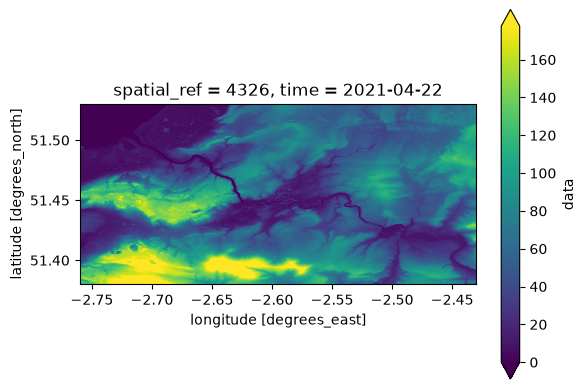

In [15]:
fig, ax = plt.subplots()
ds.plot.imshow(ax=ax, robust=True)
ax.set_aspect("equal")

Save this under a sensible name, auto-generated from parameters:

In [16]:
filename = f"{aoi_name}_copdem30.tif"

print('Saving to:', filename)

ds.rio.to_raster(filename, driver="GTiff", compress="deflate")

Saving to: bristol_copdem30.tif


An example of how to load the data:

In [17]:
ds_loaded = rxr.open_rasterio(filename, masked=True).squeeze()

ds_loaded

<xarray.DataArray 'data' (latitude: 541, longitude: 793)> Size: 2MB
array([[  0.      ,   0.      ,   0.      , ...,  72.72266 ,  72.635475,
         73.34378 ],
       [  0.      ,   0.      ,   0.      , ...,  73.51198 ,  75.5928  ,
         75.41581 ],
       [  0.      ,   0.      ,   0.      , ...,  72.91798 ,  73.82119 ,
         75.037125],
       ...,
       [124.11921 , 122.61752 , 123.91435 , ...,  54.497078,  55.014534,
         55.486084],
       [126.378746, 126.14252 , 125.087204, ...,  54.55976 ,  55.22355 ,
         55.680325],
       [127.68244 , 128.18733 , 129.83142 , ...,  55.39579 ,  55.84873 ,
         57.944416]], shape=(541, 793), dtype=float32)
Coordinates:
  * latitude     (latitude) float64 4kB 51.53 51.53 51.53 ... 51.38 51.38 51.38
  * longitude    (longitude) float64 6kB -2.76 -2.76 -2.759 ... -2.43 -2.43
    spatial_ref  int32 4B 4326
    time         datetime64[ns] 8B 2021-04-22